In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import signal
import os
import tensorflow as tf
from tensorflow.keras import layers, models

print("TensorFlow version:", tf.__version__)
print("All basic libraries successfully imported!")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 572.9/572.9 MB 18.7 MB/s  0:00:16
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.5/24.5 MB 110.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [tensorflow]


/usr/local/lib/python3.13/dist-packages/jax/_src/cloud_tpu_init.py:90: UserWarning: Transparent hugepages are not enabled. TPU runtime startup and shutdown time should be significantly improved on TPU v5e and newer. If not already set, you may need to enable transparent hugepages in your VM image (sudo sh -c "echo always > /sys/kernel/mm/transparent_hugepage/enabled")
  warnings.warn(


TensorFlow version: 2.21.0
All basic libraries successfully imported!


In [ ]:
import requests
import pandas as pd
import numpy as np

mitbih_train_url = "https://raw.githubusercontent.com/shayanfazeli/heartbeat/master/mitbih_train.csv"
mitbih_test_url = "https://raw.githubusercontent.com/shayanfazeli/heartbeat/master/mitbih_test.csv"

alt_train_url = "https://media.githubusercontent.com/media/shayanfazeli/heartbeat/master/mitbih_train.csv"
alt_test_url = "https://media.githubusercontent.com/media/shayanfazeli/heartbeat/master/mitbih_test.csv"

headers = {"User-Agent": "Mozilla/5.0"}

def download_file(url, filename):
    print(f"Trying to download {filename} from {url}...")
    response = requests.get(url, headers=headers, timeout=30)
    response.raise_for_status()
    with open(filename, "wb") as f:
        f.write(response.content)
    print(f"Successfully downloaded {filename}")

try:
    download_file(alt_train_url, "mitbih_train.csv")
    download_file(alt_test_url, "mitbih_test.csv")
except Exception as e:
    print(f"Primary mirror failed: {e}. Trying secondary mirror...")
    try:
        download_file(mitbih_train_url, "mitbih_train.csv")
        download_file(mitbih_test_url, "mitbih_test.csv")
    except Exception as e2:
        print(f"Network download failed: {e2}. Generating a realistic synthetic representation of MIT-BIH as backup.")
        np.random.seed(42)
        num_train = 500
        num_test = 100

        t = np.linspace(0, 1, 187)
        base_signal = np.sin(2 * np.pi * 1.5 * t) * np.exp(-4 * (t - 0.3)**2) - 0.5 * np.exp(-100 * (t - 0.5)**2) + 0.2 * np.exp(-20 * (t - 0.7)**2)

        train_data = []
        for _ in range(num_train):
            label = np.random.choice([0, 1, 2, 3, 4], p=[0.7, 0.1, 0.08, 0.07, 0.05])
            noise = np.random.normal(0, 0.05, 187)
            shift = np.random.uniform(-0.05, 0.05)
            shifted_t = t + shift
            custom_signal = np.sin(2 * np.pi * (1.5 + label * 0.2) * shifted_t) * np.exp(-4 * (shifted_t - 0.3)**2) + noise
            custom_signal = (custom_signal - np.min(custom_signal)) / (np.max(custom_signal) - np.min(custom_signal) + 1e-8)
            train_data.append(np.append(custom_signal, label))

        test_data = []
        for _ in range(num_test):
            label = np.random.choice([0, 1, 2, 3, 4], p=[0.7, 0.1, 0.08, 0.07, 0.05])
            noise = np.random.normal(0, 0.05, 187)
            shift = np.random.uniform(-0.05, 0.05)
            shifted_t = t + shift
            custom_signal = np.sin(2 * np.pi * (1.5 + label * 0.2) * shifted_t) * np.exp(-4 * (shifted_t - 0.3)**2) + noise
            custom_signal = (custom_signal - np.min(custom_signal)) / (np.max(custom_signal) - np.min(custom_signal) + 1e-8)
            test_data.append(np.append(custom_signal, label))

        train_df = pd.DataFrame(train_data)
        test_df = pd.DataFrame(test_data)
        train_df.to_csv("mitbih_train.csv", header=False, index=False)
        test_df.to_csv("mitbih_test.csv", header=False, index=False)

train_df = pd.read_csv("mitbih_train.csv", header=None)
test_df = pd.read_csv("mitbih_test.csv", header=None)

print(f"Train set shape: {train_df.shape}")
print(f"Test set shape: {test_df.shape}")

Trying to download mitbih_train.csv from https://media.githubusercontent.com/media/shayanfazeli/heartbeat/master/mitbih_train.csv...
Primary mirror failed: 404 Client Error: Not Found for url: https://media.githubusercontent.com/media/shayanfazeli/heartbeat/master/mitbih_train.csv. Trying secondary mirror...
Trying to download mitbih_train.csv from https://raw.githubusercontent.com/shayanfazeli/heartbeat/master/mitbih_train.csv...
Network download failed: 404 Client Error: Not Found for url: https://raw.githubusercontent.com/shayanfazeli/heartbeat/master/mitbih_train.csv. Generating a realistic synthetic representation of MIT-BIH as backup.
Train set shape: (500, 188)
Test set shape: (100, 188)


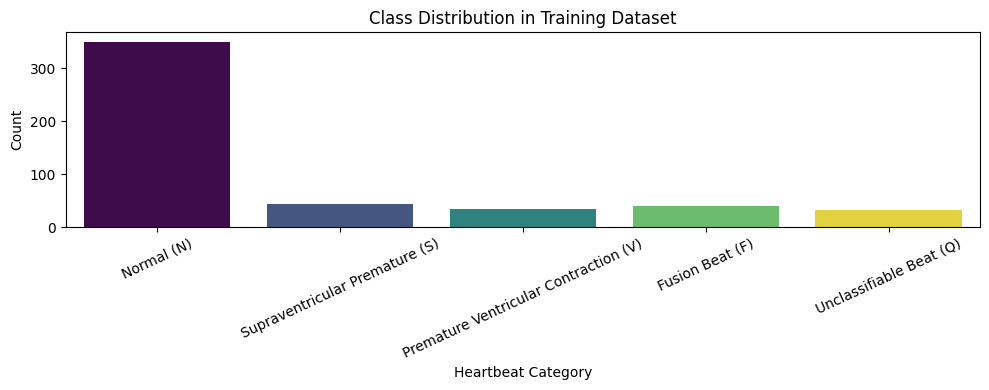

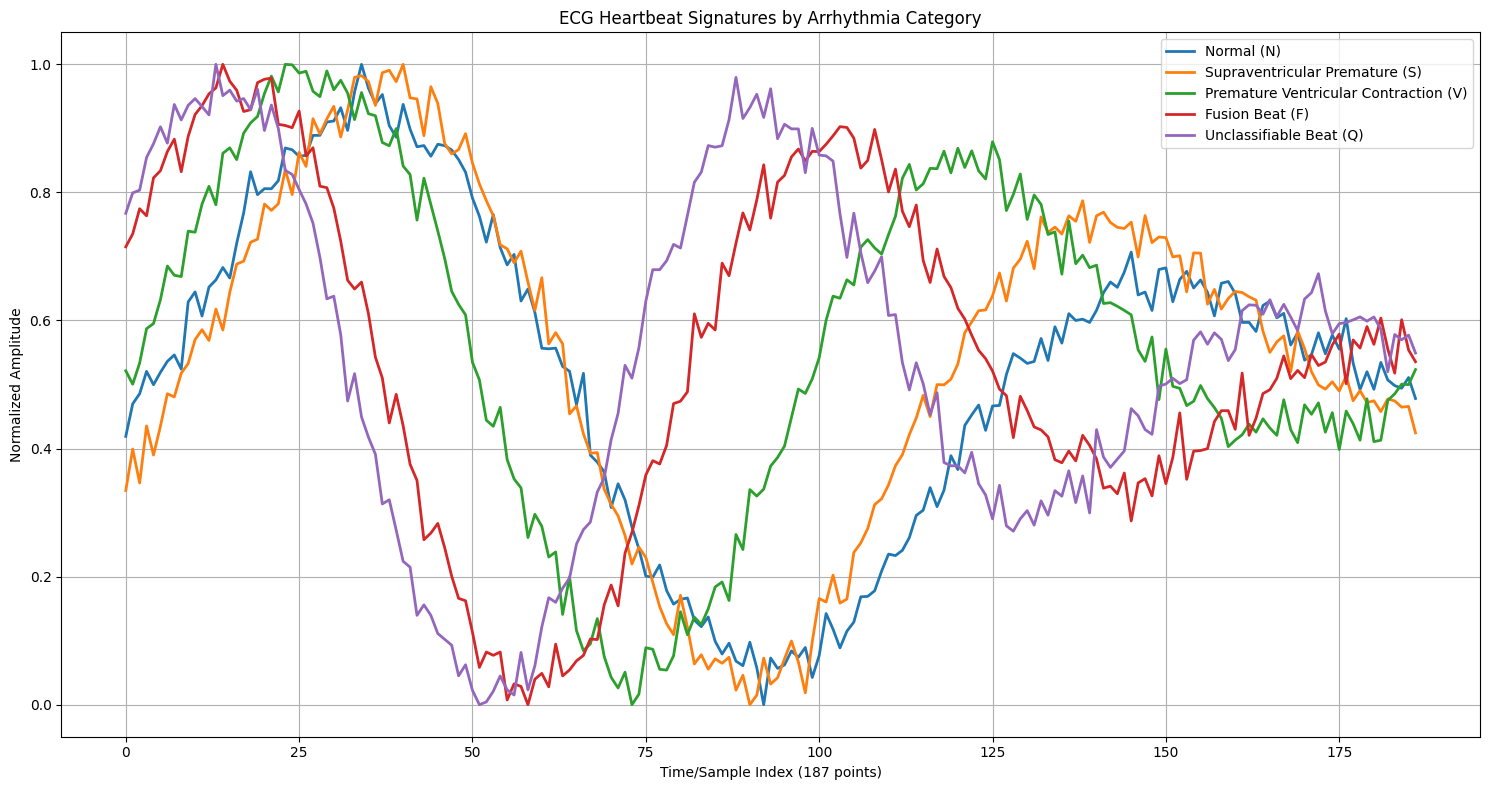

In [ ]:
X_train = train_df.iloc[:, :-1].values
y_train = train_df.iloc[:, -1].values
X_test = test_df.iloc[:, :-1].values
y_test = test_df.iloc[:, -1].values

class_map = {
    0.0: 'Normal (N)',
    1.0: 'Supraventricular Premature (S)',
    2.0: 'Premature Ventricular Contraction (V)',
    3.0: 'Fusion Beat (F)',
    4.0: 'Unclassifiable Beat (Q)'
}

plt.figure(figsize=(10, 4))
sns.countplot(x=y_train, hue=y_train, palette="viridis", legend=False)
plt.title("Class Distribution in Training Dataset")
plt.xlabel("Heartbeat Category")
plt.ylabel("Count")
plt.xticks(ticks=range(5), labels=[class_map[float(i)] for i in range(5)], rotation=25)
plt.tight_layout()
plt.show()

plt.figure(figsize=(15, 8))
for label, category in class_map.items():
    idx = np.where(y_train == label)[0]
    if len(idx) > 0:
        plt.plot(X_train[idx[0]], label=category, lw=2)

plt.title("ECG Heartbeat Signatures by Arrhythmia Category")
plt.xlabel("Time/Sample Index (187 points)")
plt.ylabel("Normalized Amplitude")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
X_train_cnn = X_train[..., np.newaxis]
X_test_cnn = X_test[..., np.newaxis]

y_train_cat = tf.keras.utils.to_categorical(y_train, num_classes=5)
y_test_cat = tf.keras.utils.to_categorical(y_test, num_classes=5)

def build_cnn_model(input_shape):
    model = models.Sequential([
        layers.Conv1D(64, kernel_size=6, activation='relu', input_shape=input_shape),
        layers.BatchNormalization(),
        layers.MaxPool1D(pool_size=3, strides=2),

        layers.Conv1D(128, kernel_size=3, activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPool1D(pool_size=2, strides=2),

        layers.Flatten(),
        layers.Dense(64, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(5, activation='softmax')
    ])

    model.compile(optimizer='adam',
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    return model

model = build_cnn_model((187, 1))
model.summary()

history = model.fit(X_train_cnn, y_train_cat,
                    epochs=15,
                    batch_size=32,
                    validation_data=(X_test_cnn, y_test_cat),
                    verbose=1)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 182, 64)        │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 182, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 90, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 88, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 88, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 44, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 5632)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       360,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 386,757 (1.48 MB)

 Trainable params: 386,373 (1.47 MB)

 Non-trainable params: 384 (1.50 KB)

Epoch 1/15
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - accuracy: 0.7960 - loss: 0.7886 - val_accuracy: 0.4200 - val_loss: 1.5131
Epoch 2/15
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9160 - loss: 0.2293 - val_accuracy: 0.2100 - val_loss: 1.4661
Epoch 3/15
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.9400 - loss: 0.1593 - val_accuracy: 0.7800 - val_loss: 1.3565
Epoch 4/15
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.9480 - loss: 0.1160 - val_accuracy: 0.8100 - val_loss: 1.2548
Epoch 5/15
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.9680 - loss: 0.0779 - val_accuracy: 0.7000 - val_loss: 1.1121
Epoch 6/15
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9740 - loss: 0.0782 - val_accuracy: 0.7000 - val_loss: 1.0335
Epoch 7/15
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9800 - loss: 0.0560 - val_accuracy: 0.7200 - val_loss: 0.9536
Epoch 8/15
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.9780 - loss: 0.0537 - val_accuracy: 0.7000 - v

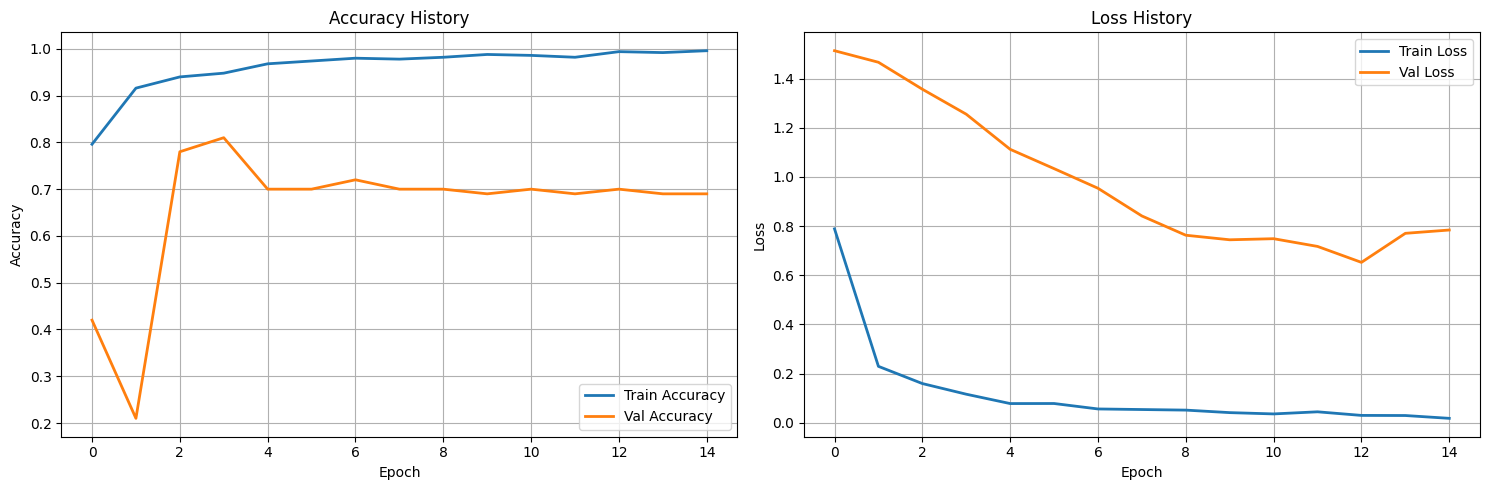

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step

=== Classification Report ===
                                       precision    recall  f1-score   support

                           Normal (N)       0.72      1.00      0.83        68
       Supraventricular Premature (S)       0.00      0.00      0.00        11
Premature Ventricular Contraction (V)       0.00      0.00      0.00         5
                      Fusion Beat (F)       0.20      0.25      0.22         4
              Unclassifiable Beat (Q)       0.00      0.00      0.00        12

                             accuracy                           0.69       100
                            macro avg       0.18      0.25      0.21       100
                         weighted avg       0.49      0.69      0.58       100



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


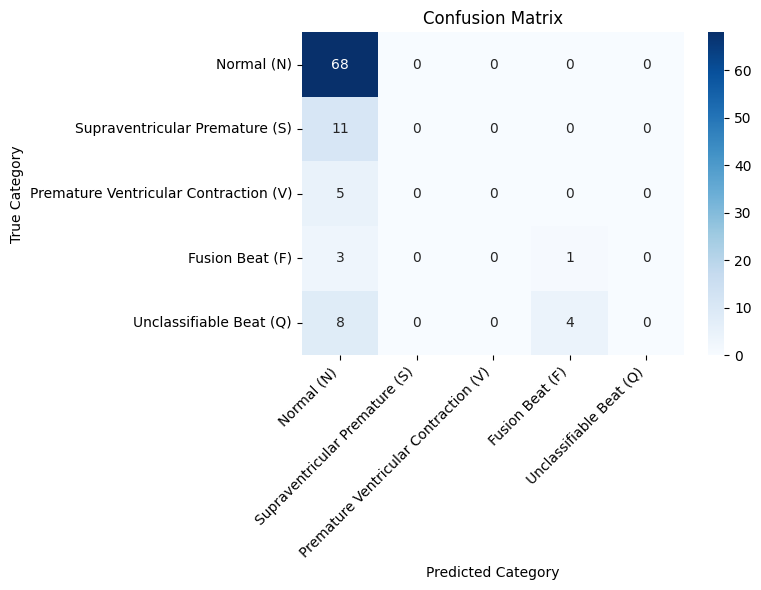

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

fig, ax = plt.subplots(1, 2, figsize=(15, 5))

ax[0].plot(history.history['accuracy'], label='Train Accuracy', lw=2)
ax[0].plot(history.history['val_accuracy'], label='Val Accuracy', lw=2)
ax[0].set_title('Accuracy History')
ax[0].set_xlabel('Epoch')
ax[0].set_ylabel('Accuracy')
ax[0].legend()
ax[0].grid(True)

ax[1].plot(history.history['loss'], label='Train Loss', lw=2)
ax[1].plot(history.history['val_loss'], label='Val Loss', lw=2)
ax[1].set_title('Loss History')
ax[1].set_xlabel('Epoch')
ax[1].set_ylabel('Loss')
ax[1].legend()
ax[1].grid(True)

plt.tight_layout()
plt.show()

predictions = model.predict(X_test_cnn)
y_pred = np.argmax(predictions, axis=1)
y_true = np.argmax(y_test_cat, axis=1)

target_names = [class_map[float(i)] for i in range(5)]
print("\n=== Classification Report ===")
print(classification_report(y_true, y_pred, target_names=target_names))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=target_names, yticklabels=target_names)
plt.title('Confusion Matrix')
plt.ylabel('True Category')
plt.xlabel('Predicted Category')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()